<a href="https://colab.research.google.com/github/Wrdone/MH/blob/main/%D0%9B%D0%A0_10_%D0%9B%D1%83%D0%BA'%D1%8F%D0%BD_10_%D0%9A%D0%B5%D1%80%D0%B0%D1%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Лук'ян Олександр
**Група:** 10 група  
**Дата:** 20.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train_raw, y_train_raw), (x_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
for name, array in [("x_train", x_train_raw), ("y_train", y_train_raw),
                    ("x_test", x_test_raw), ("y_test", y_test)]:
    print(f"{name}: {array.shape}")


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

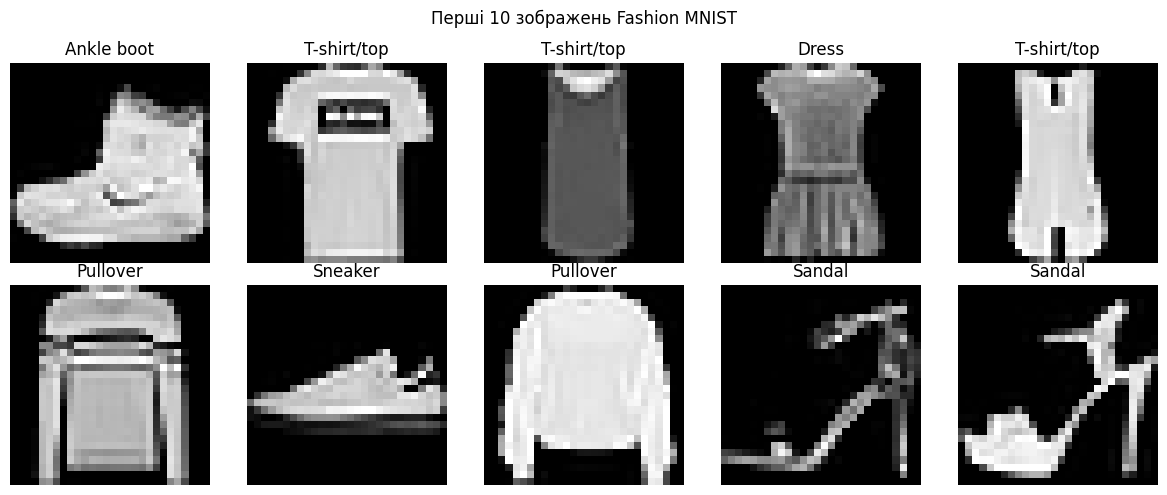

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_raw[i], cmap="gray")
    ax.set_title(class_names[y_train_raw[i]])
    ax.axis("off")
plt.suptitle("Перші 10 зображень Fashion MNIST")
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train_all = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0
# Окремі 15% навчальних даних залишаємо для валідації обох моделей.
x_train, x_val, y_train, y_val = train_test_split(
    x_train_all, y_train_raw, test_size=0.15,
    random_state=SEED, stratify=y_train_raw
)
print("Навчальна:", x_train.shape, "Валідаційна:", x_val.shape,
      "Тестова:", x_test.shape)
print("Тип:", x_train.dtype, "діапазон:", (x_train.min(), x_train.max()))
print("Тестовий діапазон:", (x_test.min(), x_test.max()))


Навчальна: (51000, 28, 28) Валідаційна: (9000, 28, 28) Тестова: (10000, 28, 28)
Тип: float32 діапазон: (np.float32(0.0), np.float32(1.0))
Тестовий діапазон: (np.float32(0.0), np.float32(1.0))


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [6]:
BASE_UNITS = [256, 128]
BASE_LR = 0.001
BASE_DROPOUT = 0.25

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(BASE_UNITS[0], activation="relu"),
    layers.Dropout(BASE_DROPOUT),
    layers.Dense(BASE_UNITS[1], activation="relu"),
    layers.Dropout(BASE_DROPOUT),
    layers.Dense(10, activation="softmax")
], name="fashion_mnist_baseline")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=BASE_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("256 і 128 нейронів - достатня місткість без надмірно великої мережі.")
print("Dropout=0.25 знижує ризик перенавчання; Adam з LR=0.001 - стандартний початок.")


256 і 128 нейронів - достатня місткість без надмірно великої мережі.
Dropout=0.25 знижує ризик перенавчання; Adam з LR=0.001 - стандартний початок.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [7]:
callbacks_base = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=2, min_lr=1e-5)
]
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25, batch_size=128,
    callbacks=callbacks_base, verbose=1
)
base_epochs = len(history.history["loss"])
print("Виконано епох:", base_epochs)


Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7842 - loss: 0.6124 - val_accuracy: 0.8538 - val_loss: 0.4023 - learning_rate: 0.0010
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8454 - loss: 0.4318 - val_accuracy: 0.8621 - val_loss: 0.3746 - learning_rate: 0.0010
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8583 - loss: 0.3898 - val_accuracy: 0.8711 - val_loss: 0.3455 - learning_rate: 0.0010
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8688 - loss: 0.3627 - val_accuracy: 0.8797 - val_loss: 0.3268 - learning_rate: 0.0010
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8722 - loss: 0.3472 - val_accuracy: 0.8787 - val_loss: 0.3257 - learning_rate: 0.0010
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8783 - loss: 0.3310 - val_accuracy: 0.8869 - val_loss: 0.3168 - learning_rate: 0.0010
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8806 - loss: 0.319

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [8]:
model.summary()
print("Кількість шарів (разом із Flatten і Dropout):", len(model.layers))
print("Кількість параметрів:", model.count_params())


Model: "fashion_mnist_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів (разом із Flatten і Dropout): 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [9]:
model.save("fashion_mnist_baseline.keras")
print("Збережено: fashion_mnist_baseline.keras")


Збережено: fashion_mnist_baseline.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

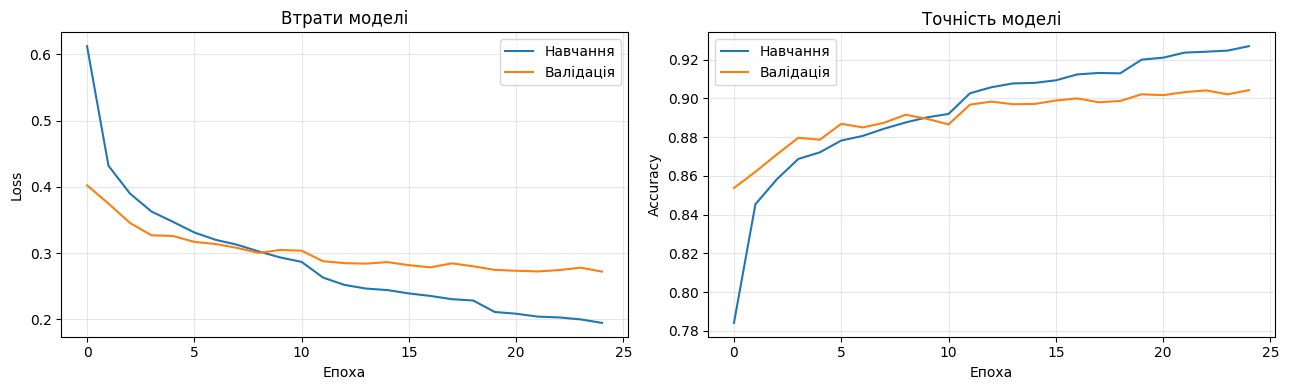

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history["loss"], label="Навчання")
axes[0].plot(history.history["val_loss"], label="Валідація")
axes[0].set(title="Втрати моделі", xlabel="Епоха", ylabel="Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history.history["accuracy"], label="Навчання")
axes[1].plot(history.history["val_accuracy"], label="Валідація")
axes[1].set(title="Точність моделі", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [11]:
base_loss, base_acc = model.evaluate(x_test, y_test, verbose=0)
base_prob = model.predict(x_test, verbose=0)
base_pred = np.argmax(base_prob, axis=1)
print(f"Тестові втрати: {base_loss:.4f}")
print(f"Тестова точність: {base_acc:.4f}")
print("Вимога accuracy >= 0.87:", "виконано" if base_acc >= 0.87 else "НЕ виконано")
print("\nКласифікаційний звіт:")
print(classification_report(y_test, base_pred, target_names=class_names, digits=4))
cm = confusion_matrix(y_test, base_pred)
errors_by_class = cm.sum(axis=1) - np.diag(cm)
for idx in np.argsort(errors_by_class)[::-1][:3]:
    print(f"Помилки для {class_names[idx]}: {errors_by_class[idx]}")


Тестові втрати: 0.3110
Тестова точність: 0.8935
Вимога accuracy >= 0.87: виконано

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8370    0.8680    0.8522      1000
     Trouser     0.9888    0.9740    0.9814      1000
    Pullover     0.7861    0.8270    0.8060      1000
       Dress     0.8779    0.9060    0.8917      1000
        Coat     0.8004    0.8260    0.8130      1000
      Sandal     0.9789    0.9730    0.9759      1000
       Shirt     0.7655    0.6560    0.7065      1000
     Sneaker     0.9489    0.9660    0.9574      1000
         Bag     0.9781    0.9810    0.9795      1000
  Ankle boot     0.9677    0.9580    0.9628      1000

    accuracy                         0.8935     10000
   macro avg     0.8929    0.8935    0.8927     10000
weighted avg     0.8929    0.8935    0.8927     10000

Помилки для Shirt: 344
Помилки для Coat: 174
Помилки для Pullover: 173


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

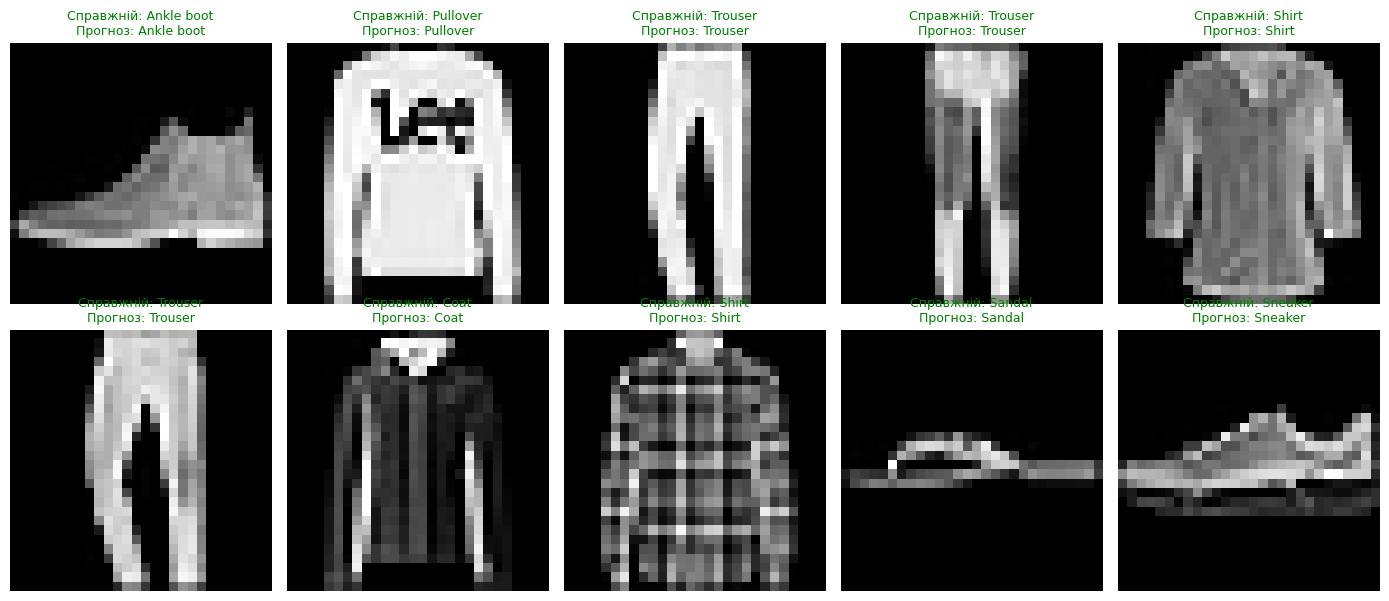

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    correct = base_pred[i] == y_test[i]
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"Справжній: {class_names[y_test[i]]}\nПрогноз: {class_names[base_pred[i]]}",
                 color="green" if correct else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()


**Проміжний висновок до завдання 1**

Після запуску кроку 9 запишіть отриману точність та проаналізуйте кількість помилок за класами.
Наведена нижче комірка автоматично формує висновок на підставі реальних результатів тестування.


In [13]:
hardest = np.argsort(errors_by_class)[::-1][:3]
print(f"Тестова точність базової моделі: {base_acc:.4f}.")
print("Цільова точність 0.87:", "досягнута." if base_acc >= 0.87 else "не досягнута.")
print("Найбільше помилок для класів:", ", ".join(class_names[k] for k in hardest))
print("Можлива причина — візуальна подібність деяких типів одягу.")


Тестова точність базової моделі: 0.8935.
Цільова точність 0.87: досягнута.
Найбільше помилок для класів: Shirt, Coat, Pullover
Можлива причина — візуальна подібність деяких типів одягу.


# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [14]:
%pip -q install keras-tuner
import keras_tuner as kt
from keras_tuner import RandomSearch
print("Keras Tuner успішно імпортовано")


Keras Tuner успішно імпортовано


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [15]:
print("Навчальна вибірка:", x_train.shape, y_train.shape)
print("Валідаційна вибірка:", x_val.shape, y_val.shape)
print("Тестова вибірка (тільки для фінального оцінювання):", x_test.shape)


Навчальна вибірка: (51000, 28, 28) (51000,)
Валідаційна вибірка: (9000, 28, 28) (9000,)
Тестова вибірка (тільки для фінального оцінювання): (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [16]:
def build_model(hp):
    net = keras.Sequential(name="fashion_mnist_tuned")
    net.add(layers.Input(shape=(28, 28)))
    net.add(layers.Flatten())
    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        dropout = hp.Float(f"dropout_{i}", min_value=0.1, max_value=0.4, step=0.1)
        l2_strength = hp.Choice(f"l2_{i}", values=[1e-5, 1e-4])
        net.add(layers.Dense(units, activation="relu",
                             kernel_regularizer=regularizers.l2(l2_strength)))
        net.add(layers.Dropout(dropout))
    net.add(layers.Dense(10, activation="softmax"))
    learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
    net.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return net


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [17]:
tuner = RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="fashion_mnist_lab10",
    overwrite=True,
    seed=SEED
)
print("Налаштовано RandomSearch: 3 спроби")


Налаштовано RandomSearch: 3 спроби


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [18]:
search_callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=2, min_lr=1e-5)
]
tuner.search(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=12, batch_size=128, callbacks=search_callbacks, verbose=1
)
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for key, value in best_hp.values.items():
    print(f"  {key}: {value}")

# Будуємо нову модель з відібраними параметрами та навчаємо її заново.
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()
tuned_history = best_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=25, batch_size=128,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                          patience=2, min_lr=1e-5)
    ], verbose=1
)
tuned_epochs = len(tuned_history.history["loss"])
best_model.save("fashion_mnist_tuned.keras")
print("Збережено: fashion_mnist_tuned.keras")


Trial 3 Complete [00h 01m 30s]
val_accuracy: 0.8775555491447449

Best val_accuracy So Far: 0.8775555491447449
Total elapsed time: 00h 03m 28s
Найкращі гіперпараметри:
  num_layers: 1
  units_0: 512
  dropout_0: 0.1
  l2_0: 0.0001
  learning_rate: 0.01
  units_1: 160
  dropout_1: 0.2
  l2_1: 0.0001


Model: "fashion_mnist_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.7947 - loss: 0.7094 - val_accuracy: 0.8299 - val_loss: 0.5482 - learning_rate: 0.0100
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8347 - loss: 0.5425 - val_accuracy: 0.8350 - val_loss: 0.5207 - learning_rate: 0.0100
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8329 - loss: 0.5501 - val_accuracy: 0.8236 - val_loss: 0.5596 - learning_rate: 0.0100
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8336 - loss: 0.5491 - val_accuracy: 0.8581 - val_loss: 0.5000 - learning_rate: 0.0100
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8337 - loss: 0.5392 - val_accuracy: 0.8628 - val_loss: 0.4745 - learning_rate: 0.0100
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8377 - loss: 0.5309 - val_accuracy: 0.8576 - val_loss: 0.4636 - learning_rate: 0.0100
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8385 - loss: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Тестові втрати після налаштування: 0.4065
Тестова точність після налаштування: 0.8690


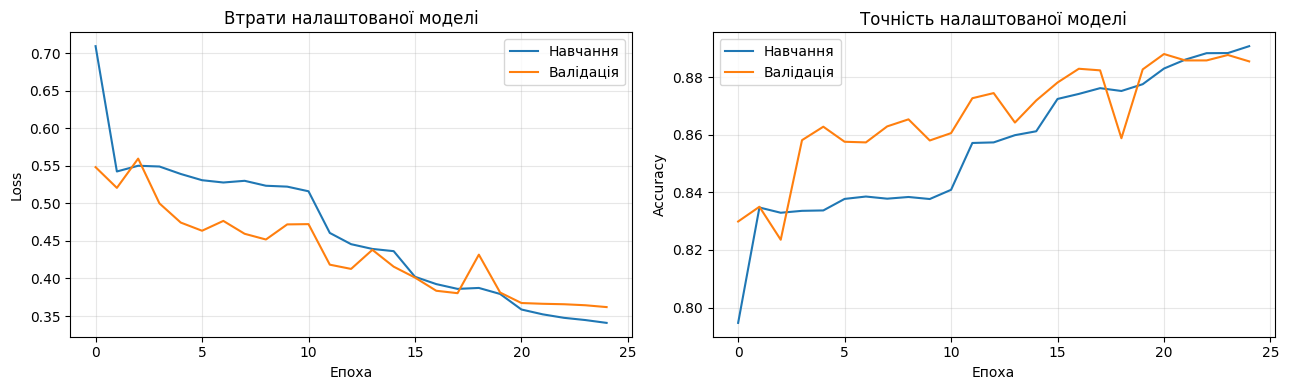

In [19]:
tuned_loss, tuned_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Тестові втрати після налаштування: {tuned_loss:.4f}")
print(f"Тестова точність після налаштування: {tuned_acc:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tuned_history.history["loss"], label="Навчання")
axes[0].plot(tuned_history.history["val_loss"], label="Валідація")
axes[0].set(title="Втрати налаштованої моделі", xlabel="Епоха", ylabel="Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(tuned_history.history["accuracy"], label="Навчання")
axes[1].plot(tuned_history.history["val_accuracy"], label="Валідація")
axes[1].set(title="Точність налаштованої моделі", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


# Висновки. Порівняння моделей

Запустіть комірку нижче після завершення обох завдань: вона автоматично створить порівняльну таблицю та висновки на основі фактичних результатів.


In [20]:
from IPython.display import display, Markdown

num_tuned = best_hp.get("num_layers")
tuned_units = [best_hp.get(f"units_{i}") for i in range(num_tuned)]
rows = [
    ("Кількість прихованих шарів", "2", str(num_tuned)),
    ("Кількість нейронів", ", ".join(map(str, BASE_UNITS)), ", ".join(map(str, tuned_units))),
    ("Швидкість навчання", f"{BASE_LR:g}", f"{best_hp.get('learning_rate'):g}"),
    ("Тестова accuracy", f"{base_acc:.4f}", f"{tuned_acc:.4f}"),
    ("Тестові loss", f"{base_loss:.4f}", f"{tuned_loss:.4f}"),
    ("Кількість епох навчання", str(base_epochs), str(tuned_epochs)),
]
table = "| Показник | Модель із завдання 1 | Модель після Keras Tuner |\n|---|---|---|\n"
table += "".join(f"| {name} | {base} | {tuned} |\n" for name, base, tuned in rows)
display(Markdown(table))

improvement = tuned_acc - base_acc
hardest = np.argsort(errors_by_class)[::-1][:3]
print("ВИСНОВКИ")
print("1. Поріг 0.87:", "досягнуто" if base_acc >= 0.87 else "не досягнуто")
print(f"2. Зміна тестової точності після налаштування: {improvement:+.4f}.")
print("   Оптимізація", "покращила" if improvement > 0 else "не покращила", "точність.")
print("3. Знайдено:", best_hp.values)
print("   Результат між запусками може відрізнятися через випадкову ініціалізацію,")
print("   випадковий пошук конфігурацій і стохастичне навчання.")
print("4. Найскладніші класи базової моделі:", ", ".join(class_names[k] for k in hardest))
print("   Часто помилки спричинені подібними силуетами та текстурами одягу.")


| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 512 |
| Швидкість навчання | 0.001 | 0.01 |
| Тестова accuracy | 0.8935 | 0.8690 |
| Тестові loss | 0.3110 | 0.4065 |
| Кількість епох навчання | 25 | 25 |


ВИСНОВКИ
1. Поріг 0.87: досягнуто
2. Зміна тестової точності після налаштування: -0.0245.
   Оптимізація не покращила точність.
3. Знайдено: {'num_layers': 1, 'units_0': 512, 'dropout_0': 0.1, 'l2_0': 0.0001, 'learning_rate': 0.01, 'units_1': 160, 'dropout_1': 0.2, 'l2_1': 0.0001}
   Результат між запусками може відрізнятися через випадкову ініціалізацію,
   випадковий пошук конфігурацій і стохастичне навчання.
4. Найскладніші класи базової моделі: Shirt, Coat, Pullover
   Часто помилки спричинені подібними силуетами та текстурами одягу.


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.